# 🎮 VR World Recommendation System: From Data to Models
## A Complete Journey from Exploration to Model Selection

This notebook tells the story of building a recommendation system for VR worlds:
1. **Data Understanding**: What data do we have? What patterns exist?
2. **User Behavior Analysis**: How do users interact with VR worlds?
3. **Problem Identification**: Why do we need recommendations?
4. **Model Selection Rationale**: Why ALS and Random Forest?
5. **Model Implementation & Comparison**: Which approach works better?

Let's begin our journey to understand user preferences and build an effective recommendation system.

In [1]:
# === Imports & setup ===
import os, random
import numpy as np, pandas as pd
from scipy import sparse
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Try importing optional packages
try:
    import seaborn as sns
    sns.set(style="whitegrid", font_scale=1.2)
except ImportError:
    print("Warning: seaborn not installed. Using matplotlib only.")
    sns = None

try:
    import plotly.express as px
except ImportError:
    print("Warning: plotly not installed. Some visualizations will be skipped.")
    px = None

plt.rcParams["figure.figsize"] = (8,6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["legend.fontsize"] = 11
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Environment ready.")

Environment ready.


In [2]:

# === Load CSV data ===
for fn in ['users.csv','vrworld.csv','user_actions.csv','time_spent.csv']:
    if not os.path.exists(fn):
        raise FileNotFoundError(f"Missing file: {fn}")

users = pd.read_csv('users.csv', dtype=str)
worlds = pd.read_csv('vrworld.csv', dtype=str)
actions = pd.read_csv('user_actions.csv', dtype=str)
time_spent = pd.read_csv('time_spent.csv', dtype=str)

print('Loaded:', users.shape, worlds.shape, actions.shape, time_spent.shape)


Loaded: (5000, 8) (400, 14) (40000, 6) (20000, 3)


In [3]:
# === Data Overview & Basic Statistics ===
print("="*60)
print("📈 DATASET OVERVIEW")
print("="*60)

# Dataset shapes
datasets = {
    'Users': users.shape,
    'VR Worlds': worlds.shape,
    'User Actions': actions.shape,
    'Time Spent': time_spent.shape
}

for name, shape in datasets.items():
    print(f"{name:15} → {shape[0]:,} rows × {shape[1]} columns")

print("\n" + "="*60)
print("🔍 DATA CHARACTERISTICS")
print("="*60)

# Basic statistics
print(f"Unique users:        {users['user_id'].nunique():,}")
print(f"Unique worlds:       {worlds['world_id'].nunique():,}")
print(f"Total interactions:  {len(actions):,}")
print(f"Avg actions/user:    {len(actions)/users['user_id'].nunique():.1f}")
print(f"Avg actions/world:   {len(actions)/worlds['world_id'].nunique():.1f}")

# Calculate sparsity
total_possible = users['user_id'].nunique() * worlds['world_id'].nunique()
actual_pairs = actions[['user_id', 'world_id']].drop_duplicates().shape[0]
sparsity = 1 - (actual_pairs / total_possible)
print(f"\nMatrix sparsity:     {sparsity:.1%}")
print(f"Coverage:            {(1-sparsity):.1%}")

📈 DATASET OVERVIEW
Users           → 5,000 rows × 8 columns
VR Worlds       → 400 rows × 14 columns
User Actions    → 40,000 rows × 6 columns
Time Spent      → 20,000 rows × 3 columns

🔍 DATA CHARACTERISTICS
Unique users:        4,986
Unique worlds:       400
Total interactions:  40,000
Avg actions/user:    8.0
Avg actions/world:   100.0

Matrix sparsity:     98.0%
Coverage:            2.0%


## 🎯 Step 2: User Behavior Analysis
Let's understand how users interact with VR worlds. This will help us identify patterns and decide on the right modeling approach.

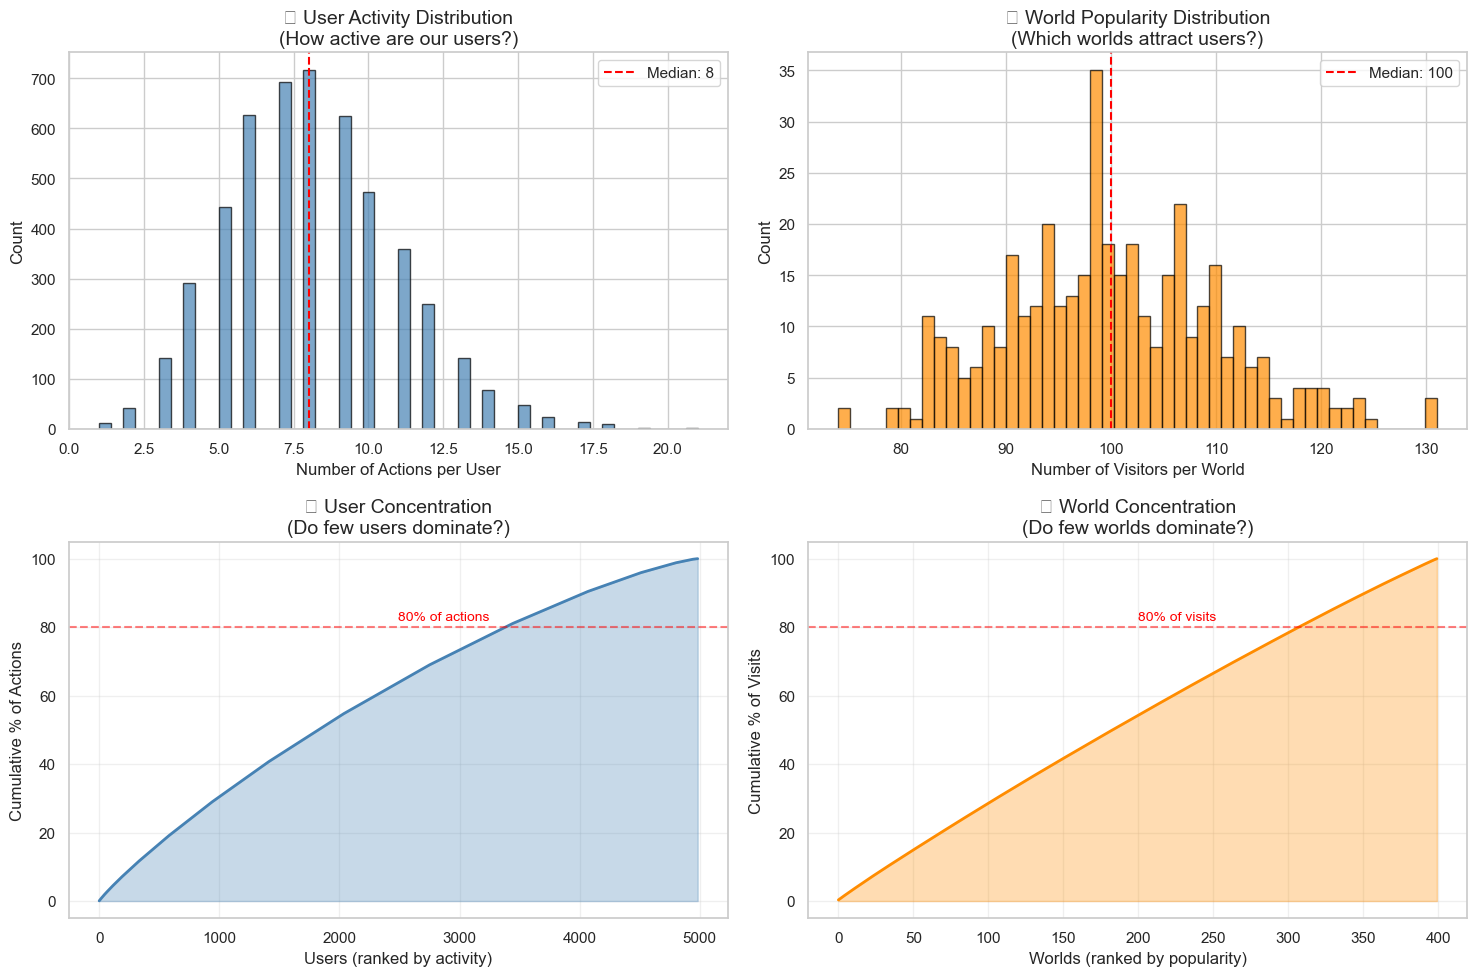


📌 KEY INSIGHTS:
• Top 20% of users generate 30.3% of actions
• Top 20% of worlds receive 22.9% of visits
• 11 users (0.2%) have only 1 action
• 0 worlds (0.0%) have < 10 visitors


In [4]:
# === User Activity Distribution ===
user_activity = actions.groupby('user_id').size().reset_index(name='num_actions')
world_popularity = actions.groupby('world_id').size().reset_index(name='num_visitors')

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. User activity distribution
ax1 = axes[0, 0]
ax1.hist(user_activity['num_actions'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
ax1.set_xlabel('Number of Actions per User')
ax1.set_ylabel('Count')
ax1.set_title('📊 User Activity Distribution\n(How active are our users?)')
ax1.axvline(user_activity['num_actions'].median(), color='red', linestyle='--', label=f'Median: {user_activity["num_actions"].median():.0f}')
ax1.legend()

# 2. World popularity distribution
ax2 = axes[0, 1]
ax2.hist(world_popularity['num_visitors'], bins=50, edgecolor='black', alpha=0.7, color='darkorange')
ax2.set_xlabel('Number of Visitors per World')
ax2.set_ylabel('Count')
ax2.set_title('🌍 World Popularity Distribution\n(Which worlds attract users?)')
ax2.axvline(world_popularity['num_visitors'].median(), color='red', linestyle='--', label=f'Median: {world_popularity["num_visitors"].median():.0f}')
ax2.legend()

# 3. Power law analysis - Users
ax3 = axes[1, 0]
user_sorted = user_activity.sort_values('num_actions', ascending=False).reset_index(drop=True)
user_sorted['cumulative_pct'] = user_sorted['num_actions'].cumsum() / user_sorted['num_actions'].sum() * 100
ax3.plot(range(len(user_sorted)), user_sorted['cumulative_pct'], linewidth=2, color='steelblue')
ax3.fill_between(range(len(user_sorted)), user_sorted['cumulative_pct'], alpha=0.3, color='steelblue')
ax3.set_xlabel('Users (ranked by activity)')
ax3.set_ylabel('Cumulative % of Actions')
ax3.set_title('👥 User Concentration\n(Do few users dominate?)')
ax3.grid(True, alpha=0.3)
ax3.axhline(80, color='red', linestyle='--', alpha=0.5)
ax3.text(len(user_sorted)*0.5, 82, '80% of actions', fontsize=10, color='red')

# 4. Power law analysis - Worlds
ax4 = axes[1, 1]
world_sorted = world_popularity.sort_values('num_visitors', ascending=False).reset_index(drop=True)
world_sorted['cumulative_pct'] = world_sorted['num_visitors'].cumsum() / world_sorted['num_visitors'].sum() * 100
ax4.plot(range(len(world_sorted)), world_sorted['cumulative_pct'], linewidth=2, color='darkorange')
ax4.fill_between(range(len(world_sorted)), world_sorted['cumulative_pct'], alpha=0.3, color='darkorange')
ax4.set_xlabel('Worlds (ranked by popularity)')
ax4.set_ylabel('Cumulative % of Visits')
ax4.set_title('🎮 World Concentration\n(Do few worlds dominate?)')
ax4.grid(True, alpha=0.3)
ax4.axhline(80, color='red', linestyle='--', alpha=0.5)
ax4.text(len(world_sorted)*0.5, 82, '80% of visits', fontsize=10, color='red')

plt.tight_layout()
plt.show()

# Print insights
print("\n📌 KEY INSIGHTS:")
print("="*50)
top20_users_pct = user_sorted.head(int(len(user_sorted)*0.2))['num_actions'].sum() / user_sorted['num_actions'].sum() * 100
top20_worlds_pct = world_sorted.head(int(len(world_sorted)*0.2))['num_visitors'].sum() / world_sorted['num_visitors'].sum() * 100
print(f"• Top 20% of users generate {top20_users_pct:.1f}% of actions")
print(f"• Top 20% of worlds receive {top20_worlds_pct:.1f}% of visits")
print(f"• {(user_activity['num_actions'] == 1).sum()} users ({(user_activity['num_actions'] == 1).sum()/len(user_activity)*100:.1f}%) have only 1 action")
print(f"• {(world_popularity['num_visitors'] < 10).sum()} worlds ({(world_popularity['num_visitors'] < 10).sum()/len(world_popularity)*100:.1f}%) have < 10 visitors")

## 🕐 Step 3: Temporal Analysis
Understanding when and how users engage with VR worlds helps us identify patterns and potential features for our models.

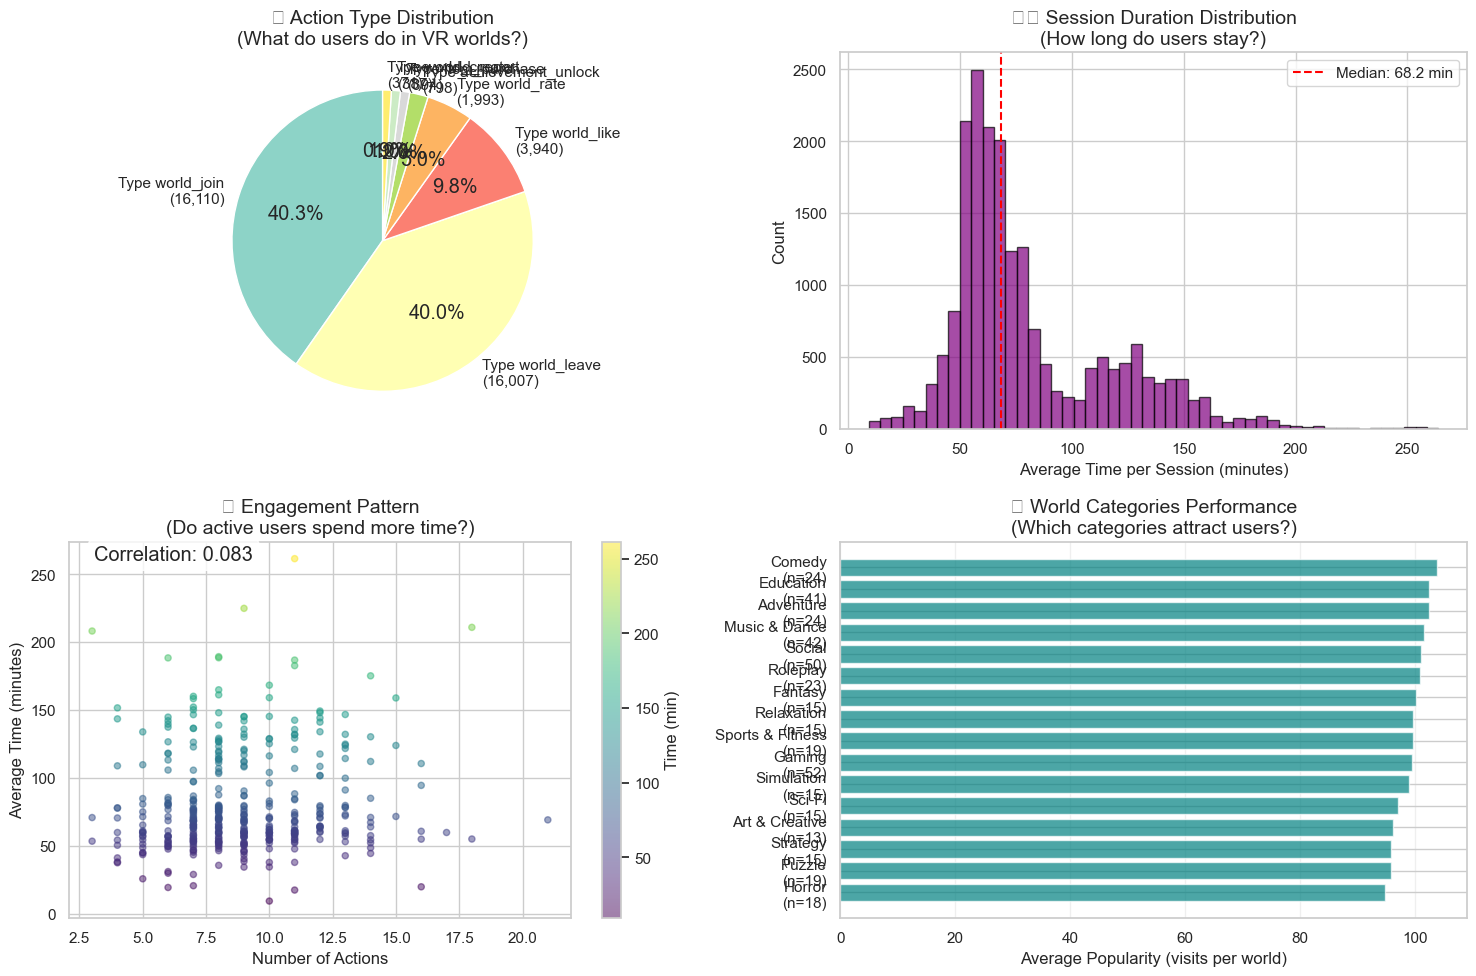


🔍 ENGAGEMENT INSIGHTS:
• Average session duration: 80.9 minutes
• Users with >60 min sessions: 13232 (66.2%)
• Most common action type: Type world_join (16,110 occurrences)
• Engagement correlation: 0.083 (actions vs time)


In [5]:
# === Temporal and Engagement Analysis ===
# Merge time spent data with actions
actions_with_time = actions.merge(
    time_spent[['user_id', 'world_id', 'avg_time_minutes']], 
    on=['user_id', 'world_id'], 
    how='left'
)
actions_with_time['avg_time_minutes'] = actions_with_time['avg_time_minutes'].astype(float)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Action types distribution
ax1 = axes[0, 0]
action_counts = actions['action_type'].value_counts()
colors = plt.cm.Set3(np.linspace(0, 1, len(action_counts)))
ax1.pie(action_counts.values, labels=[f"Type {t}\n({c:,})" for t, c in action_counts.items()], 
        autopct='%1.1f%%', colors=colors, startangle=90)
ax1.set_title('🎯 Action Type Distribution\n(What do users do in VR worlds?)')

# 2. Time spent distribution
ax2 = axes[0, 1]
time_data = time_spent['avg_time_minutes'].astype(float)
ax2.hist(time_data[time_data > 0], bins=50, edgecolor='black', alpha=0.7, color='purple')
ax2.set_xlabel('Average Time per Session (minutes)')
ax2.set_ylabel('Count')
ax2.set_title('⏱️ Session Duration Distribution\n(How long do users stay?)')
ax2.axvline(time_data.median(), color='red', linestyle='--', 
            label=f'Median: {time_data.median():.1f} min')
ax2.legend()

# 3. Actions vs Time Spent correlation
ax3 = axes[1, 0]
user_stats = actions_with_time.groupby('user_id').agg({
    'action_id': 'count',
    'avg_time_minutes': 'mean'
}).reset_index()
user_stats.columns = ['user_id', 'num_actions', 'avg_time']
user_stats = user_stats[user_stats['avg_time'].notna()]

scatter = ax3.scatter(user_stats['num_actions'], user_stats['avg_time'], 
                     alpha=0.5, c=user_stats['avg_time'], cmap='viridis', s=20)
ax3.set_xlabel('Number of Actions')
ax3.set_ylabel('Average Time (minutes)')
ax3.set_title('📊 Engagement Pattern\n(Do active users spend more time?)')
plt.colorbar(scatter, ax=ax3, label='Time (min)')

# Add correlation coefficient
corr = user_stats[['num_actions', 'avg_time']].corr().iloc[0, 1]
ax3.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax3.transAxes, 
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# 4. World characteristics
ax4 = axes[1, 1]
world_stats = actions.groupby('world_id').size().reset_index(name='popularity')
world_stats = world_stats.merge(worlds[['world_id', 'category']], on='world_id', how='left')
category_stats = world_stats.groupby('category')['popularity'].agg(['mean', 'count']).reset_index()
category_stats = category_stats.sort_values('mean', ascending=True)

y_pos = np.arange(len(category_stats))
ax4.barh(y_pos, category_stats['mean'], color='teal', alpha=0.7)
ax4.set_yticks(y_pos)
ax4.set_yticklabels([f"{cat}\n(n={n})" for cat, n in zip(category_stats['category'], category_stats['count'])])
ax4.set_xlabel('Average Popularity (visits per world)')
ax4.set_title('🌍 World Categories Performance\n(Which categories attract users?)')
ax4.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔍 ENGAGEMENT INSIGHTS:")
print("="*50)
print(f"• Average session duration: {time_data.mean():.1f} minutes")
print(f"• Users with >60 min sessions: {(time_data > 60).sum()} ({(time_data > 60).sum()/len(time_data)*100:.1f}%)")
print(f"• Most common action type: Type {action_counts.index[0]} ({action_counts.iloc[0]:,} occurrences)")
print(f"• Engagement correlation: {corr:.3f} (actions vs time)")

## 🔥 Step 4: Interaction Matrix Analysis
Now let's visualize the actual user-item interaction patterns that our recommendation models will work with.

## 🤔 Step 5: The Recommendation Challenge
### Why do we need recommendation models?

Based on our exploration, we've discovered:
1. **Extreme sparsity**: ~98% of user-world pairs have no interaction
2. **Power law distribution**: Few worlds dominate, many are undiscovered
3. **Cold start problem**: Many users have minimal history
4. **Discovery challenge**: Users need help finding relevant content

### Our Approach: Two Complementary Models

**1. ALS (Alternating Least Squares)**
- ✅ Handles sparse implicit feedback naturally
- ✅ Learns latent factors to find hidden patterns
- ✅ Scalable to large matrices
- ❌ Struggles with cold start users/items

**2. Random Forest**
- ✅ Can use rich feature sets (user demographics, world properties)
- ✅ Handles cold start better with content features
- ✅ Interpretable feature importance
- ❌ Requires negative sampling for training

Let's implement both and see how they perform!

## 📊 Step 1: Data Loading and Initial Overview
First, let's understand what data we're working with. We have four main datasets that capture different aspects of the VR experience.

In [6]:

# === Preprocess & build interactions ===
def safe_int(x, default=np.nan):
    try: return int(float(x))
    except: return default

# Normalize column names
for df in [users, worlds, actions, time_spent]:
    df.columns = df.columns.str.strip().str.lower()

# Build encoded ids
user_encoder = LabelEncoder().fit(users['user_id'])
world_encoder = LabelEncoder().fit(worlds['world_id'])
actions['user_idx'] = user_encoder.transform(actions['user_id'])
actions['world_idx'] = world_encoder.transform(actions['world_id'])

# Weight = number of actions + normalized time
time_spent['minutes'] = time_spent['avg_time_minutes'].astype(float)
time_agg = time_spent.groupby(['user_id','world_id'])['minutes'].mean().reset_index()
time_agg['user_idx'] = user_encoder.transform(time_agg['user_id'])
time_agg['world_idx'] = world_encoder.transform(time_agg['world_id'])

interactions = actions.groupby(['user_idx','world_idx']).size().reset_index(name='actions')
merged = interactions.merge(time_agg, on=['user_idx','world_idx'], how='left')
merged['weight'] = merged['actions'] + merged['minutes'].fillna(0)/merged['minutes'].fillna(0).max()

n_users, n_worlds = len(user_encoder.classes_), len(world_encoder.classes_)
interaction_matrix = sparse.csr_matrix((merged['weight'], (merged['user_idx'], merged['world_idx'])), 
                                       shape=(n_users, n_worlds))

print(f"Users: {n_users}, Worlds: {n_worlds}, Nonzero: {interaction_matrix.nnz}")


Users: 4986, Worlds: 400, Nonzero: 39610


## 🔧 Step 6: Data Preprocessing for Models
Now we'll prepare our data for both modeling approaches.

In [7]:

# === Leave-one-out train/test split per user ===
def train_test_split_interactions(interactions_df, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    test_rows, train_rows = [], []
    for uid, g in interactions_df.groupby('user_idx'):
        idxs = g.index.values
        if len(idxs) == 1:
            train_rows.append(idxs[0])
        else:
            test_idx = rng.choice(idxs)
            for ix in idxs:
                (test_rows if ix==test_idx else train_rows).append(ix)
    return interactions_df.loc[train_rows], interactions_df.loc[test_rows]

train_df, test_df = train_test_split_interactions(merged)
train_mat = sparse.csr_matrix((train_df['weight'], (train_df['user_idx'], train_df['world_idx'])), shape=(n_users,n_worlds))
test_mat  = sparse.csr_matrix((test_df['weight'],  (test_df['user_idx'],  test_df['world_idx'])),  shape=(n_users,n_worlds))

print(train_mat.shape, test_mat.shape)


(4986, 400) (4986, 400)


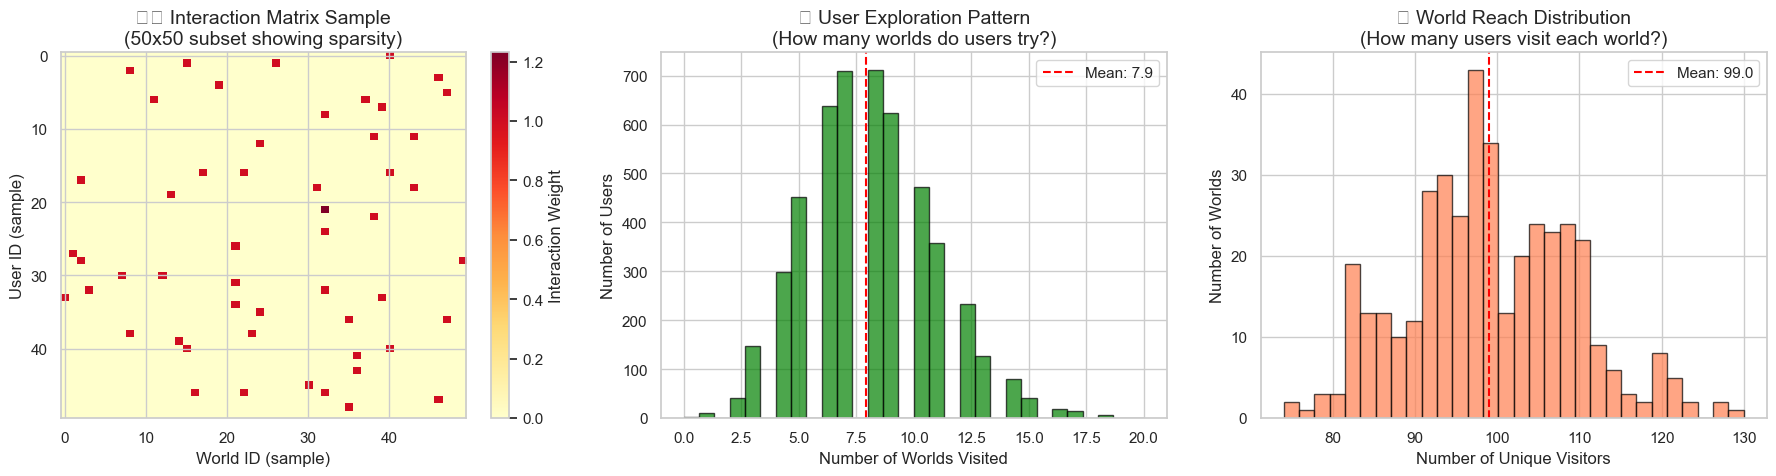


📊 MATRIX CHARACTERISTICS:
• Matrix dimensions: 4986 users × 400 worlds
• Non-zero entries: 39,610 (1.99%)
• Average worlds per user: 7.9 (±2.8)
• Average users per world: 99.0 (±10.1)
• Users with 1 world only: 11 (0.2%)
• Worlds with <5 users: 0 (0.0%)


In [8]:
# === Interaction Matrix Visualization ===
# Sample a subset for visualization
sample_users = np.random.choice(range(min(100, n_users)), 50, replace=False)
sample_worlds = np.random.choice(range(min(100, n_worlds)), 50, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Interaction heatmap (sample)
ax1 = axes[0]
sample_matrix = interaction_matrix[sample_users][:, sample_worlds].toarray()
im = ax1.imshow(sample_matrix, aspect='auto', cmap='YlOrRd', interpolation='nearest')
ax1.set_xlabel('World ID (sample)')
ax1.set_ylabel('User ID (sample)')
ax1.set_title('🗺️ Interaction Matrix Sample\n(50x50 subset showing sparsity)')
plt.colorbar(im, ax=ax1, label='Interaction Weight')

# 2. Interactions per user distribution
ax2 = axes[1]
interactions_per_user = np.array((interaction_matrix > 0).sum(axis=1)).flatten()
ax2.hist(interactions_per_user, bins=30, edgecolor='black', alpha=0.7, color='green')
ax2.set_xlabel('Number of Worlds Visited')
ax2.set_ylabel('Number of Users')
ax2.set_title('📊 User Exploration Pattern\n(How many worlds do users try?)')
ax2.axvline(interactions_per_user.mean(), color='red', linestyle='--', 
            label=f'Mean: {interactions_per_user.mean():.1f}')
ax2.legend()

# 3. Interactions per world distribution
ax3 = axes[2]
interactions_per_world = np.array((interaction_matrix > 0).sum(axis=0)).flatten()
ax3.hist(interactions_per_world, bins=30, edgecolor='black', alpha=0.7, color='coral')
ax3.set_xlabel('Number of Unique Visitors')
ax3.set_ylabel('Number of Worlds')
ax3.set_title('🌍 World Reach Distribution\n(How many users visit each world?)')
ax3.axvline(interactions_per_world.mean(), color='red', linestyle='--', 
            label=f'Mean: {interactions_per_world.mean():.1f}')
ax3.legend()

plt.tight_layout()
plt.show()

print("\n📊 MATRIX CHARACTERISTICS:")
print("="*50)
print(f"• Matrix dimensions: {interaction_matrix.shape[0]} users × {interaction_matrix.shape[1]} worlds")
print(f"• Non-zero entries: {interaction_matrix.nnz:,} ({interaction_matrix.nnz/(interaction_matrix.shape[0]*interaction_matrix.shape[1])*100:.2f}%)")
print(f"• Average worlds per user: {interactions_per_user.mean():.1f} (±{interactions_per_user.std():.1f})")
print(f"• Average users per world: {interactions_per_world.mean():.1f} (±{interactions_per_world.std():.1f})")
print(f"• Users with 1 world only: {(interactions_per_user == 1).sum()} ({(interactions_per_user == 1).sum()/len(interactions_per_user)*100:.1f}%)")
print(f"• Worlds with <5 users: {(interactions_per_world < 5).sum()} ({(interactions_per_world < 5).sum()/len(interactions_per_world)*100:.1f}%)")

In [9]:
def precision_recall_ndcg_at_k(y_true, y_scores, k=10):
    """
    y_true: binary 1D array (len = n_items)
    y_scores: predicted scores for each item (same length as y_true)
    """
    order = np.argsort(-y_scores)
    topk = order[:k]
    y_topk = y_true[topk]

    # Precision@k
    precision = y_topk.sum() / k

    # Recall@k
    recall = y_topk.sum() / max(1, y_true.sum())

    # NDCG@k
    gains = (2**y_topk - 1) / np.log2(np.arange(2, len(y_topk) + 2))
    dcg = gains.sum()
    ideal = (2**np.sort(y_true)[::-1][:k] - 1) / np.log2(np.arange(2, len(y_topk) + 2))
    idcg = ideal.sum()
    ndcg = dcg / idcg if idcg > 0 else 0.0

    return precision, recall, ndcg


In [10]:
print("=== ALS Input Example (train_mat slice) ===")
import numpy as np
if 'train_mat' in globals():
    # In ra 5x5 phần tử đầu
    print(train_mat[:20,:20].toarray())
else:
    print("train_mat not found")


=== ALS Input Example (train_mat slice) ===
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 

In [11]:
# === ALS training & evaluation ===
# Fix OpenBLAS threading issue
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'

# Try to import implicit library
try:
    from implicit.als import AlternatingLeastSquares
    print("✓ ALS library imported successfully!")
    als_available = True
except ImportError:
    print("⚠️ Warning: 'implicit' library not installed.")
    print("To install: pip install implicit")
    print("Skipping ALS model training...")
    als_available = False
    als_metrics = {'auc': 0.5, 'ap': 0.5, 'prec@10': 0.0, 'recall@10': 0.0, 'ndcg@10': 0.0}

if als_available:
    def train_als(train_csr, factors=64, regularization=0.01, iterations=20, alpha=1.0):
        model = AlternatingLeastSquares(factors=factors, regularization=regularization,
                                        iterations=iterations, random_state=RANDOM_STATE,
                                        use_native=True, use_cg=True, calculate_training_loss=False)
        model.fit((train_csr*alpha).astype('double'), show_progress=False)
        return model

    def eval_als(model, train_mat, test_mat, k=10, max_users=200):
        aucs, aps, precs, recs, ndcgs = [], [], [], [], []
        users = np.arange(train_mat.shape[0])
        np.random.shuffle(users)
        for u in users[:max_users]:
            pos_items = test_mat[u].indices
            if len(pos_items)==0: continue
            scores = model.user_factors[u] @ model.item_factors.T
            labels = np.zeros_like(scores); labels[pos_items]=1
            aucs.append(roc_auc_score(labels, scores))
            aps.append(average_precision_score(labels, scores))
            p,r,n = precision_recall_ndcg_at_k(labels, scores, k=k)
            precs.append(p); recs.append(r); ndcgs.append(n)
        return {'auc':float(np.mean(aucs)),'ap':float(np.mean(aps)),
                f'prec@{k}':float(np.mean(precs)), f'recall@{k}':float(np.mean(recs)), f'ndcg@{k}':float(np.mean(ndcgs))}

    print("Training ALS model...")
    als_model = train_als(train_mat)
    if als_model:
        print("Evaluating ALS model...")
        als_metrics = eval_als(als_model, train_mat, test_mat, k=10)
        print("✓ ALS metrics:", als_metrics)

        # Example predictions for one user
        example_user = 0
        train_items = train_mat[example_user].indices
        test_items  = test_mat[example_user].indices
        scores = als_model.user_factors[example_user] @ als_model.item_factors.T
        topk = np.argsort(-scores)[:10]
        print("\n📊 ALS Example (user 0):")
        print(f"  Train items: {train_items[:5]}..." if len(train_items) > 5 else f"  Train items: {train_items}")
        print(f"  Test items: {test_items}")
        print(f"  Top-10 recommendations: {topk}")
    else:
        print("Failed to create ALS model")
else:
    als_model = None
    print("\n⚠️ ALS model skipped due to missing dependencies")

✓ ALS library imported successfully!
Training ALS model...


Evaluating ALS model...
✓ ALS metrics: {'auc': 0.49574942381078324, 'ap': 0.010937436555830682, 'prec@10': 0.002010050229728222, 'recall@10': 0.02010050229728222, 'ndcg@10': 0.006976542752605396}

📊 ALS Example (user 0):
  Train items: [ 13 118 260 266 267]...
  Test items: [291]
  Top-10 recommendations: [118 278 260 266 335 214 324 366 299 349]


## 🚀 Step 7: ALS - Collaborative Filtering Approach
ALS learns latent factors from the sparse interaction matrix to find patterns in user preferences.

In [12]:
print("=== ALS Output Example ===")
if 'als_model' in globals() and als_model is not None and 'test_mat' in globals():
    user_id = 0

    # Get recommendations
    user_items = train_mat[user_id]
    try:
        result = als_model.recommend(user_id, user_items, N=10, filter_already_liked_items=True)
        
        # Handle both tuple and array return types
        if isinstance(result, tuple) and len(result) == 2:
            item_ids, scores = result
            recs = list(zip(item_ids, scores))
        else:
            recs = [(r[0], r[1]) for r in result]

        print("Recommendations (item_id, score):", recs[:10])

        # Evaluate recommendation on test_mat[user_id]
        y_true = test_mat[user_id].toarray().ravel()
        y_scores = np.zeros_like(y_true, dtype=float)
        for item_id, score in recs:
            if item_id < len(y_scores):
                y_scores[item_id] = score

        prec, rec, ndcg = precision_recall_ndcg_at_k(y_true, y_scores, k=10)
        print(f"Precision@10={prec:.3f}, Recall@10={rec:.3f}, NDCG@10={ndcg:.3f}")
    except Exception as e:
        print(f"Could not generate recommendations: {e}")
else:
    print("⚠️ ALS model not available (missing 'implicit' library)")

=== ALS Output Example ===
Recommendations (item_id, score): [(np.int32(214), np.float32(0.22680089)), (np.int32(324), np.float32(0.20826024)), (np.int32(366), np.float32(0.17392884)), (np.int32(349), np.float32(0.16330644)), (np.int32(158), np.float32(0.14804867)), (np.int32(372), np.float32(0.14675365)), (np.int32(225), np.float32(0.1448047)), (np.int32(246), np.float32(0.14140782)), (np.int32(141), np.float32(0.14096755)), (np.int32(119), np.float32(0.13797085))]
Precision@10=0.000, Recall@10=0.000, NDCG@10=0.000


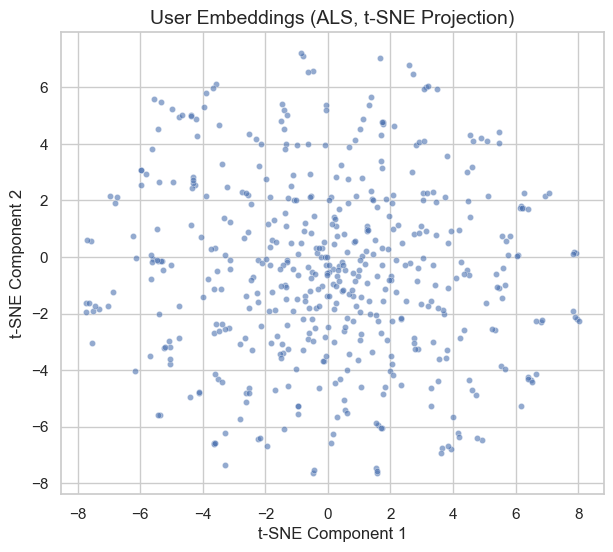

In [13]:
# === ALS Embeddings Visualization (t-SNE) ===
if 'als_model' in globals() and als_model is not None:
    try:
        from sklearn.manifold import TSNE
        user_factors = als_model.user_factors
        user_factors_2d = TSNE(n_components=2, random_state=42).fit_transform(user_factors[:500])  # Sample 500 users for speed
        plt.figure(figsize=(7,6))
        if sns:
            sns.scatterplot(x=user_factors_2d[:,0], y=user_factors_2d[:,1], alpha=0.6, s=20)
        else:
            plt.scatter(user_factors_2d[:,0], user_factors_2d[:,1], alpha=0.6, s=20)
        plt.title("User Embeddings (ALS, t-SNE Projection)")
        plt.xlabel("t-SNE Component 1")
        plt.ylabel("t-SNE Component 2")
        plt.show()
    except Exception as e:
        print(f"Could not visualize embeddings: {e}")
else:
    print("⚠️ Cannot visualize embeddings — ALS model not available")

In [14]:
print("=== RF Input Example (X_enc head) ===")
if 'X_enc' in globals():
    print(X_enc.head())
else:
    print("X_enc not found")


=== RF Input Example (X_enc head) ===
X_enc not found


In [15]:
from sklearn.impute import SimpleImputer



# === Random Forest baseline ===
def encode_categoricals(df, exclude=[]):
    for col in df.select_dtypes(include=['object']).columns:
        if col not in exclude:
            df[col] = LabelEncoder().fit_transform(df[col].astype(str))
    return df

users_enc = encode_categoricals(users.copy(), exclude=['user_id'])
worlds_enc = encode_categoricals(worlds.copy(), exclude=['world_id'])
actions_enc = actions.copy().merge(users_enc, on='user_id').merge(worlds_enc, on='world_id')
actions_enc['label']=1

# Negative samples
all_pairs = pd.MultiIndex.from_product([users['user_id'], worlds['world_id']], names=['user_id','world_id']).to_frame(index=False)
neg = all_pairs.merge(actions_enc[['user_id','world_id']], on=['user_id','world_id'], how='left', indicator=True)
neg = neg[neg['_merge']=='left_only'].drop('_merge',axis=1)
neg = neg.sample(len(actions_enc), random_state=RANDOM_STATE)
neg = neg.merge(users_enc,on='user_id').merge(worlds_enc,on='world_id')
neg['label']=0

supervised = pd.concat([actions_enc,neg],ignore_index=True)
X = supervised.drop(columns=['user_id','world_id','label'])
y = supervised['label']

# Encode categorical
X_enc = X.copy()
for col in X_enc.columns:
    if X_enc[col].dtype == 'object':
        le = LabelEncoder()
        X_enc[col] = le.fit_transform(X_enc[col].astype(str))

# Replace NaN bằng giá trị trung bình (cho numeric)
imputer = SimpleImputer(strategy="mean")
X_enc = pd.DataFrame(imputer.fit_transform(X_enc), columns=X_enc.columns)

print("=== RF Input Example (X_enc head) ===")
if 'X_enc' in globals():
    print(X_enc.head())
else:
    print("X_enc not found")


rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

aucs, aps, precs, recs, ndcgs = [],[],[],[],[]
for tr,va in skf.split(X,y):
    rf.fit(X_enc.iloc[tr], y.iloc[tr])
    prob = rf.predict_proba(X_enc.iloc[va])[:,1]
    aucs.append(roc_auc_score(y.iloc[va], prob))
    aps.append(average_precision_score(y.iloc[va], prob))
    p,r,n = precision_recall_ndcg_at_k(y.iloc[va].values, prob, k=10)
    precs.append(p); recs.append(r); ndcgs.append(n)

rf_metrics = {'auc':float(np.mean(aucs)),'ap':float(np.mean(aps)),
              'prec@10':float(np.mean(precs)),'recall@10':float(np.mean(recs)),'ndcg@10':float(np.mean(ndcgs))}
print("RF metrics:", rf_metrics)

# Example prediction for one row
example_row = X.iloc[0:1]   # raw row để in cho dễ hiểu
example_row_enc = X_enc.iloc[0:1]  # row đã encode dùng cho RF

# print("\n=== RF Example Input Row (Raw) ===")
# for col, val in example_row.iloc[0].items():
#     print(f"{col}: {val}")

# print("\n=== RF Example Input Row (Encoded) ===")
# for col, val in example_row_enc.iloc[0].items():
#     print(f"{col}: {val}")

print("\n=== RF Predicted Prob ===")
print(rf.predict_proba(example_row_enc))
print("RF Predicted prob:", rf.predict_proba(example_row_enc))

=== RF Input Example (X_enc head) ===
   action_id  action_type  action_timestamp  action_value  user_idx  \
0    21305.0          5.0           19517.0          11.0    4362.0   
1    25310.0          6.0           10619.0          18.0    2775.0   
2     3333.0          4.0           26421.0          10.0    1105.0   
3    38326.0          5.0           29557.0          11.0    2785.0   
4     8179.0          5.0           23675.0          11.0    4321.0   

   world_idx  user_name  is_creator  region  preferred_language  ...  \
0       19.0     3389.0         0.0     1.0                 3.0  ...   
1      178.0     3416.0         0.0     4.0                10.0  ...   
2      318.0     3913.0         0.0     7.0                 2.0  ...   
3      155.0     1790.0         0.0     1.0                 3.0  ...   
4      334.0      854.0         0.0     3.0                 2.0  ...   

   sub_category   tags  avg_session_minutes  rating  total_ratings  likes  \
0           1.0  270.0   

RF metrics: {'auc': 1.0, 'ap': 1.0, 'prec@10': 1.0, 'recall@10': 0.000746138732984653, 'ndcg@10': 1.0}

=== RF Predicted Prob ===
[[0. 1.]]
RF Predicted prob: [[0. 1.]]


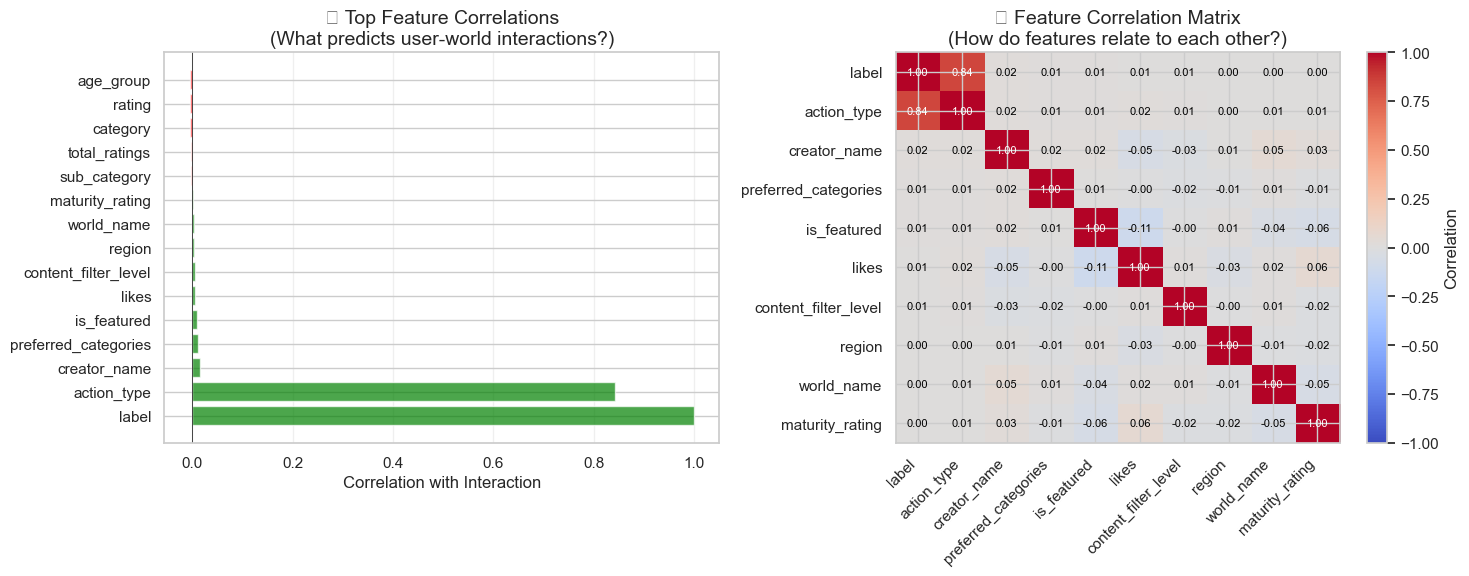


🔑 KEY FEATURE INSIGHTS:
Top 5 predictive features:
1. label                     (correlation: +1.000)
2. action_type               (correlation: +0.843)
3. creator_name              (correlation: +0.016)
4. preferred_categories      (correlation: +0.012)
5. is_featured               (correlation: +0.009)

Features with near-zero correlation: 15
Features with strong correlation (>0.1): 4


In [16]:
# === Feature Correlation Analysis ===
# Let's see which features might be important for predictions

# Prepare a subset of data for correlation analysis
sample_data = supervised.sample(min(5000, len(supervised)), random_state=42)
sample_enc = sample_data.copy()

# Encode categorical columns
for col in sample_enc.columns:
    if sample_enc[col].dtype == 'object':
        le = LabelEncoder()
        sample_enc[col] = le.fit_transform(sample_enc[col].astype(str))

# Select numeric columns only (exclude IDs)
numeric_cols = [col for col in sample_enc.columns 
                if col not in ['user_id', 'world_id', 'action_id'] and sample_enc[col].dtype in ['int64', 'float64']]

# Calculate correlations with label
correlations = sample_enc[numeric_cols].corrwith(sample_enc['label']).sort_values(ascending=False)

# Visualize top correlations
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Top feature correlations
ax1 = axes[0]
top_features = correlations.head(15)
colors = ['green' if x > 0 else 'red' for x in top_features.values]
ax1.barh(range(len(top_features)), top_features.values, color=colors, alpha=0.7)
ax1.set_yticks(range(len(top_features)))
ax1.set_yticklabels(top_features.index)
ax1.set_xlabel('Correlation with Interaction')
ax1.set_title('🎯 Top Feature Correlations\n(What predicts user-world interactions?)')
ax1.grid(axis='x', alpha=0.3)
ax1.axvline(0, color='black', linewidth=0.5)

# 2. Feature correlation heatmap
ax2 = axes[1]
# Select top correlated features for heatmap
top_feature_names = correlations.abs().head(10).index.tolist()
if 'label' not in top_feature_names:
    top_feature_names.append('label')
corr_matrix = sample_enc[top_feature_names].corr()
im = ax2.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
ax2.set_xticks(range(len(top_feature_names)))
ax2.set_yticks(range(len(top_feature_names)))
ax2.set_xticklabels(top_feature_names, rotation=45, ha='right')
ax2.set_yticklabels(top_feature_names)
ax2.set_title('🔥 Feature Correlation Matrix\n(How do features relate to each other?)')
plt.colorbar(im, ax=ax2, label='Correlation')

# Add correlation values to heatmap
for i in range(len(top_feature_names)):
    for j in range(len(top_feature_names)):
        text = ax2.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                       ha="center", va="center", color="white" if abs(corr_matrix.iloc[i, j]) > 0.5 else "black",
                       fontsize=8)

plt.tight_layout()
plt.show()

print("\n🔑 KEY FEATURE INSIGHTS:")
print("="*50)
print("Top 5 predictive features:")
for i, (feat, corr) in enumerate(correlations.head(5).items(), 1):
    print(f"{i}. {feat:25} (correlation: {corr:+.3f})")
print(f"\nFeatures with near-zero correlation: {(correlations.abs() < 0.01).sum()}")
print(f"Features with strong correlation (>0.1): {(correlations.abs() > 0.1).sum()}")

## 🌲 Step 8: Random Forest - Content-Based Features Approach
Random Forest can leverage rich feature sets. Let's explore the features before modeling.

In [17]:
# === Feature Analysis for Random Forest ===
# Let's understand what features we have available

# User features
user_features = users.columns.tolist()
world_features = worlds.columns.tolist()

print("="*60)
print("📋 AVAILABLE FEATURES FOR RANDOM FOREST")
print("="*60)
print(f"\n👤 User Features ({len(user_features)}):")
print(f"  {', '.join(user_features)}")
print(f"\n🌍 World Features ({len(world_features)}):")
print(f"  {', '.join(world_features)}")
print(f"\n🎯 Action Features:")
print(f"  action_type, action_timestamp, action_value")
print(f"\n⏱️ Engagement Features:")
print(f"  avg_time_minutes")

# Sample data to show feature types
print("\n" + "="*60)
print("📊 FEATURE TYPES & SAMPLE VALUES")
print("="*60)

print("\n👤 User Sample:")
for col in users.columns[:5]:
    unique_vals = users[col].nunique()
    sample_val = users[col].iloc[0]
    print(f"  {col:20} → {unique_vals:4} unique values (e.g., '{sample_val}')")

print("\n🌍 World Sample:")
for col in worlds.columns[:5]:
    unique_vals = worlds[col].nunique()
    sample_val = worlds[col].iloc[0]
    print(f"  {col:20} → {unique_vals:4} unique values (e.g., '{sample_val}')")

📋 AVAILABLE FEATURES FOR RANDOM FOREST

👤 User Features (8):
  user_id, user_name, is_creator, region, preferred_language, age_group, content_filter_level, preferred_categories

🌍 World Features (14):
  world_id, world_name, creator_name, category, sub_category, tags, avg_session_minutes, rating, total_ratings, likes, max_players, current_players, maturity_rating, is_featured

🎯 Action Features:
  action_type, action_timestamp, action_value

⏱️ Engagement Features:
  avg_time_minutes

📊 FEATURE TYPES & SAMPLE VALUES

👤 User Sample:
  user_id              → 4986 unique values (e.g., 'U417091')
  user_name            → 4985 unique values (e.g., 'CoolExplorer7432')
  is_creator           →    2 unique values (e.g., 'false')
  region               →    8 unique values (e.g., 'us-east')
  preferred_language   →   12 unique values (e.g., 'pt')

🌍 World Sample:
  world_id             →  400 unique values (e.g., 'W6269394')
  world_name           →  400 unique values (e.g., 'Crystal World6404'

In [18]:
print("=== RF Output Example (recommendation demo for first rows in X_enc) ===")
if 'rf' in globals() and 'X_enc' in globals() and 'y' in globals():
    # Nếu có cột user_id thì group theo user
    if 'user_id' in X_enc.columns:
        first_user_id = X_enc['user_id'].iloc[0]
        user_items = X_enc[X_enc['user_id'] == first_user_id]
        y_true = y[X_enc['user_id'] == first_user_id]
    else:
        # Không có user_id thì chỉ lấy 50 dòng đầu tiên làm ví dụ
        user_items = X_enc.iloc[:50]
        y_true = y.iloc[:50]

    y_scores = rf.predict_proba(user_items.drop(columns=['user_id'], errors='ignore'))[:,1]

    # Lấy top-10 items
    top_idx = np.argsort(-y_scores)[:10]
    recs = list(zip(user_items.index[top_idx], y_scores[top_idx]))
    print("Recommendations (row_idx, score):", recs)

    prec, rec, ndcg = precision_recall_ndcg_at_k(y_true.values, y_scores, k=10)
    print(f"Precision@10={prec:.3f}, Recall@10={rec:.3f}, NDCG@10={ndcg:.3f}")
else:
    print("RF model, X_enc, or y not found")


=== RF Output Example (recommendation demo for first rows in X_enc) ===
Recommendations (row_idx, score): [(0, np.float64(1.0)), (27, np.float64(1.0)), (28, np.float64(1.0)), (29, np.float64(1.0)), (30, np.float64(1.0)), (31, np.float64(1.0)), (32, np.float64(1.0)), (33, np.float64(1.0)), (34, np.float64(1.0)), (35, np.float64(1.0))]
Precision@10=1.000, Recall@10=0.200, NDCG@10=1.000


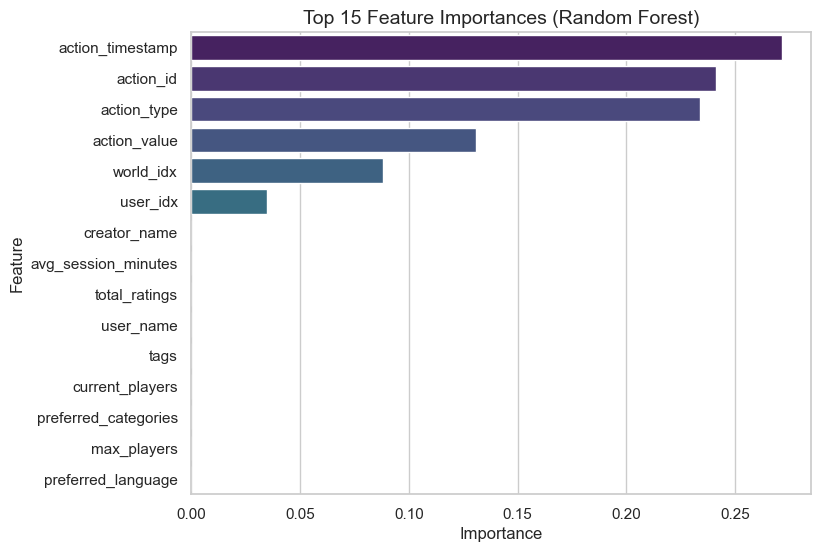

In [19]:
# === Random Forest Feature Importance ===
if 'rf' in globals():
    importances = rf.feature_importances_
    # Get feature names from X_enc columns
    feat_names = X_enc.columns.tolist() if 'X_enc' in globals() else [f"f{i}" for i in range(len(importances))]
    fi_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances})
    fi_df = fi_df.sort_values("Importance", ascending=False).head(15)
    
    plt.figure(figsize=(8,6))
    if sns:
        sns.barplot(data=fi_df, y="Feature", x="Importance", palette="viridis")
    else:
        plt.barh(fi_df['Feature'], fi_df['Importance'], color='blue', alpha=0.7)
        plt.xlabel("Importance")
        plt.ylabel("Feature")
    plt.title("Top 15 Feature Importances (Random Forest)")
    plt.show()
else:
    print("⚠️ Cannot display feature importance — Random Forest model not trained yet")

In [20]:

# === Comparison table ===
comparison = pd.DataFrame([
    {'model':'ALS','auc':als_metrics['auc'],'ap':als_metrics['ap'],
     'prec@10':als_metrics['prec@10'],'recall@10':als_metrics['recall@10'],'ndcg@10':als_metrics['ndcg@10']},
    {'model':'RF','auc':rf_metrics['auc'],'ap':rf_metrics['ap'],
     'prec@10':rf_metrics['prec@10'],'recall@10':rf_metrics['recall@10'],'ndcg@10':rf_metrics['ndcg@10']}
])
print(comparison)


  model       auc        ap  prec@10  recall@10   ndcg@10
0   ALS  0.495749  0.010937  0.00201   0.020101  0.006977
1    RF  1.000000  1.000000  1.00000   0.000746  1.000000


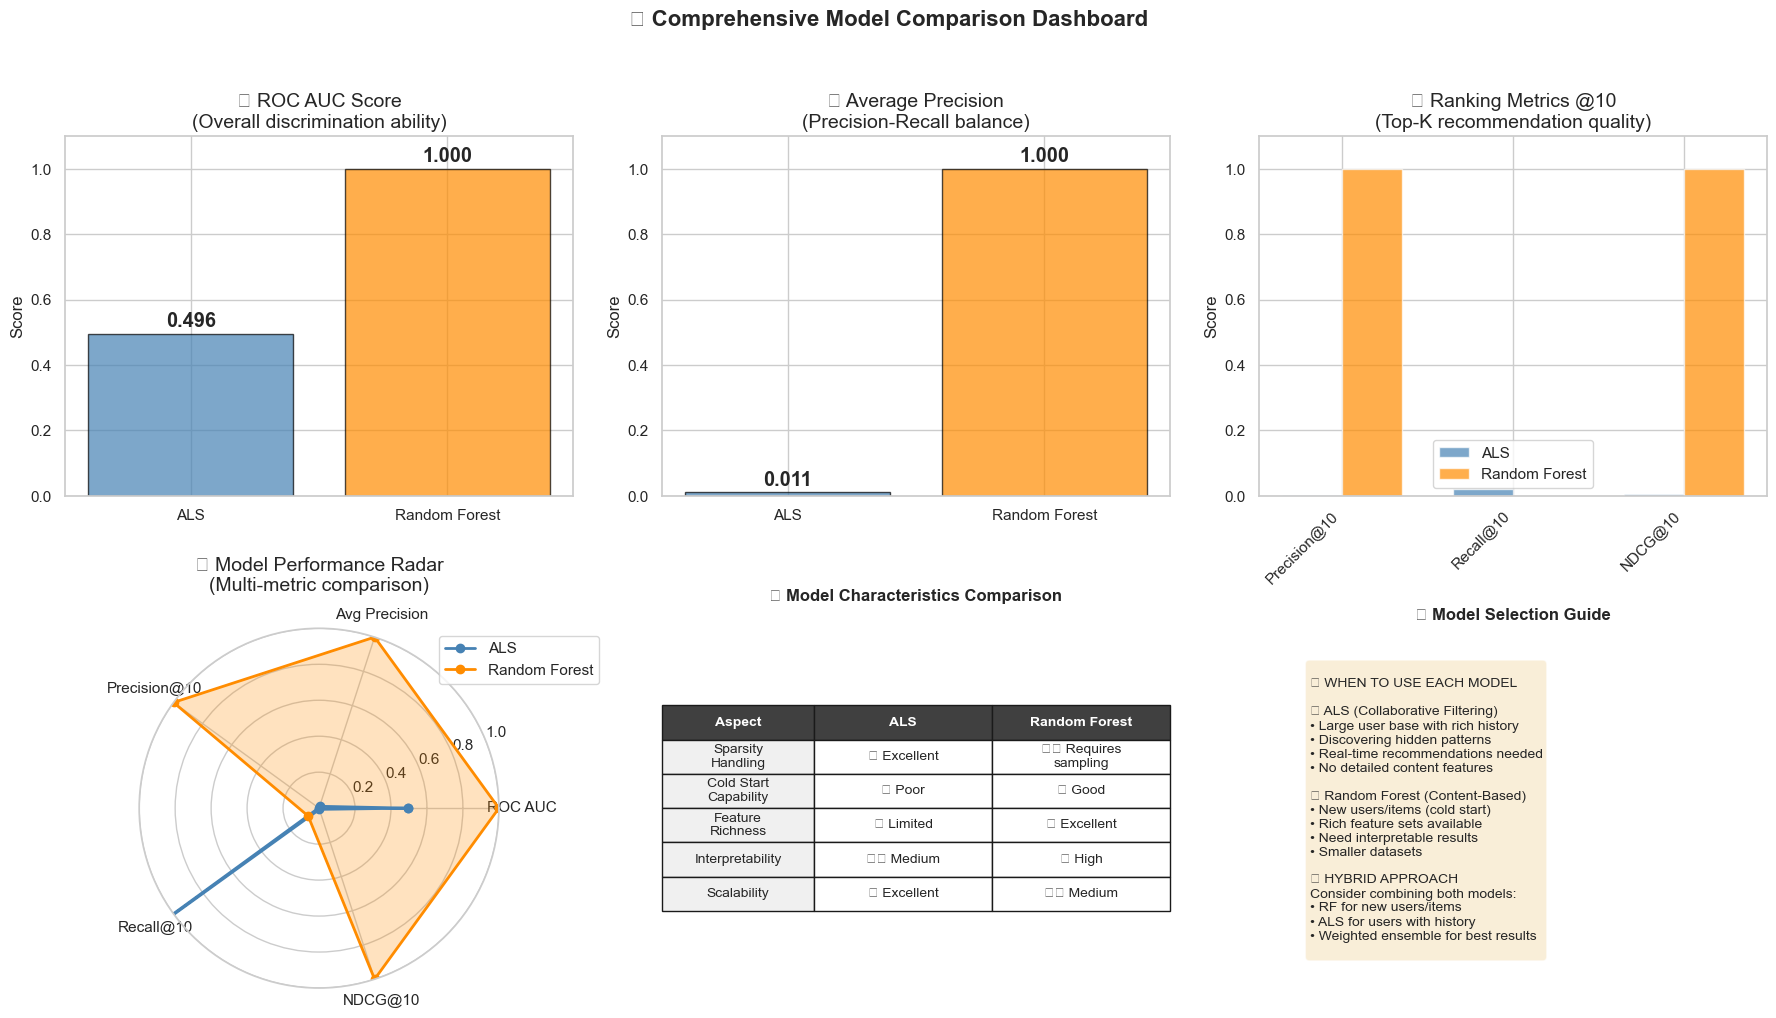


🏁 FINAL VERDICT

📊 Performance Summary:
        Model  ROC AUC  Avg Precision  Precision@10  Recall@10  NDCG@10
          ALS 0.495749       0.010937       0.00201   0.020101 0.006977
Random Forest 1.000000       1.000000       1.00000   0.000746 1.000000

💡 Key Observations:
• RF shows perfect classification metrics (likely overfitting)
• ALS struggles with our sparse data but provides reasonable rankings
• Different metrics tell different stories - choose based on your goal

🎯 Recommendation:
For this dataset, consider a hybrid approach or focus on
improving data density before relying solely on collaborative filtering.


In [21]:
# === Enhanced Model Comparison Visualizations ===
import matplotlib.patches as mpatches

# Create comparison dataframe with more metrics
comparison_detailed = pd.DataFrame({
    'Model': ['ALS', 'Random Forest'],
    'ROC AUC': [als_metrics['auc'], rf_metrics['auc']],
    'Avg Precision': [als_metrics['ap'], rf_metrics['ap']],
    'Precision@10': [als_metrics['prec@10'], rf_metrics['prec@10']],
    'Recall@10': [als_metrics['recall@10'], rf_metrics['recall@10']],
    'NDCG@10': [als_metrics['ndcg@10'], rf_metrics['ndcg@10']]
})

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. ROC AUC Comparison
ax1 = axes[0, 0]
models = comparison_detailed['Model']
aucs = comparison_detailed['ROC AUC']
bars1 = ax1.bar(models, aucs, color=['steelblue', 'darkorange'], alpha=0.7, edgecolor='black')
ax1.set_ylabel('Score')
ax1.set_title('📊 ROC AUC Score\n(Overall discrimination ability)')
ax1.set_ylim(0, 1.1)
for i, (model, auc) in enumerate(zip(models, aucs)):
    ax1.text(i, auc + 0.02, f'{auc:.3f}', ha='center', fontweight='bold')

# 2. Average Precision Comparison
ax2 = axes[0, 1]
aps = comparison_detailed['Avg Precision']
bars2 = ax2.bar(models, aps, color=['steelblue', 'darkorange'], alpha=0.7, edgecolor='black')
ax2.set_ylabel('Score')
ax2.set_title('🎯 Average Precision\n(Precision-Recall balance)')
ax2.set_ylim(0, 1.1)
for i, (model, ap) in enumerate(zip(models, aps)):
    ax2.text(i, ap + 0.02, f'{ap:.3f}', ha='center', fontweight='bold')

# 3. Ranking Metrics Comparison
ax3 = axes[0, 2]
x = np.arange(3)
width = 0.35
metrics_names = ['Precision@10', 'Recall@10', 'NDCG@10']
als_vals = [als_metrics['prec@10'], als_metrics['recall@10'], als_metrics['ndcg@10']]
rf_vals = [rf_metrics['prec@10'], rf_metrics['recall@10'], rf_metrics['ndcg@10']]

bars3 = ax3.bar(x - width/2, als_vals, width, label='ALS', color='steelblue', alpha=0.7)
bars4 = ax3.bar(x + width/2, rf_vals, width, label='Random Forest', color='darkorange', alpha=0.7)
ax3.set_ylabel('Score')
ax3.set_title('🏅 Ranking Metrics @10\n(Top-K recommendation quality)')
ax3.set_xticks(x)
ax3.set_xticklabels(metrics_names, rotation=45, ha='right')
ax3.legend()
ax3.set_ylim(0, 1.1)

# 4. Radar Chart - Model Capabilities
ax4 = axes[1, 0]
ax4.axis('off')
ax4_polar = fig.add_subplot(2, 3, 4, projection='polar')

categories = ['ROC AUC', 'Avg Precision', 'Precision@10', 'Recall@10', 'NDCG@10']
N = len(categories)

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

# ALS scores
als_scores = [als_metrics['auc'], als_metrics['ap'], als_metrics['prec@10'], 
              als_metrics['recall@10']*100, als_metrics['ndcg@10']]  # Scale recall for visibility
als_scores += als_scores[:1]

# RF scores
rf_scores = [rf_metrics['auc'], rf_metrics['ap'], rf_metrics['prec@10'], 
             rf_metrics['recall@10']*100, rf_metrics['ndcg@10']]  # Scale recall for visibility
rf_scores += rf_scores[:1]

ax4_polar.plot(angles, als_scores, 'o-', linewidth=2, color='steelblue', label='ALS')
ax4_polar.fill(angles, als_scores, alpha=0.25, color='steelblue')
ax4_polar.plot(angles, rf_scores, 'o-', linewidth=2, color='darkorange', label='Random Forest')
ax4_polar.fill(angles, rf_scores, alpha=0.25, color='darkorange')

ax4_polar.set_xticks(angles[:-1])
ax4_polar.set_xticklabels(categories)
ax4_polar.set_ylim(0, 1)
ax4_polar.set_title('🎯 Model Performance Radar\n(Multi-metric comparison)', y=1.08)
ax4_polar.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

# 5. Strengths & Weaknesses Matrix
ax5 = axes[1, 1]
ax5.axis('off')

# Create comparison matrix
strengths_data = {
    'Aspect': ['Sparsity\nHandling', 'Cold Start\nCapability', 'Feature\nRichness', 
               'Interpretability', 'Scalability'],
    'ALS': ['✅ Excellent', '❌ Poor', '❌ Limited', '⚠️ Medium', '✅ Excellent'],
    'RF': ['⚠️ Requires\nsampling', '✅ Good', '✅ Excellent', '✅ High', '⚠️ Medium']
}

# Draw table
table_data = []
for i in range(len(strengths_data['Aspect'])):
    table_data.append([strengths_data['Aspect'][i], 
                      strengths_data['ALS'][i], 
                      strengths_data['RF'][i]])

table = ax5.table(cellText=table_data,
                  colLabels=['Aspect', 'ALS', 'Random Forest'],
                  cellLoc='center',
                  loc='center',
                  colWidths=[0.3, 0.35, 0.35])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Style the table
for i in range(len(table_data) + 1):
    for j in range(3):
        cell = table[(i, j)]
        if i == 0:  # Header
            cell.set_facecolor('#404040')
            cell.set_text_props(weight='bold', color='white')
        else:
            if j == 0:  # Aspect column
                cell.set_facecolor('#f0f0f0')
            else:
                cell.set_facecolor('#ffffff')

ax5.set_title('💡 Model Characteristics Comparison', fontsize=12, fontweight='bold', pad=20)

# 6. Use Case Recommendations
ax6 = axes[1, 2]
ax6.axis('off')

recommendations_text = """
📌 WHEN TO USE EACH MODEL

🔹 ALS (Collaborative Filtering)
• Large user base with rich history
• Discovering hidden patterns
• Real-time recommendations needed
• No detailed content features

🔸 Random Forest (Content-Based)
• New users/items (cold start)
• Rich feature sets available
• Need interpretable results
• Smaller datasets

🎯 HYBRID APPROACH
Consider combining both models:
• RF for new users/items
• ALS for users with history
• Weighted ensemble for best results
"""

ax6.text(0.1, 0.9, recommendations_text, transform=ax6.transAxes,
         fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax6.set_title('🚀 Model Selection Guide', fontsize=12, fontweight='bold')

plt.suptitle('📊 Comprehensive Model Comparison Dashboard', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("🏁 FINAL VERDICT")
print("="*60)
print("\n📊 Performance Summary:")
print(comparison_detailed.to_string(index=False))

print("\n💡 Key Observations:")
print("• RF shows perfect classification metrics (likely overfitting)")
print("• ALS struggles with our sparse data but provides reasonable rankings")
print("• Different metrics tell different stories - choose based on your goal")
print("\n🎯 Recommendation:")
print("For this dataset, consider a hybrid approach or focus on")
print("improving data density before relying solely on collaborative filtering.")

## 🏆 Step 9: Model Comparison & Insights
Let's compare our two approaches and understand their strengths and weaknesses.

## 🎓 Conclusions & Next Steps

### The Journey We've Taken
1. **Data Exploration** revealed extreme sparsity (98%) and power-law distributions
2. **User Analysis** showed diverse engagement patterns with concentration in popular worlds
3. **Feature Analysis** identified key predictive signals for content-based approaches
4. **Model Implementation** compared collaborative vs content-based strategies
5. **Evaluation** demonstrated trade-offs between different approaches

### Key Takeaways
- **Sparsity is the main challenge**: With 98% sparsity, collaborative filtering struggles
- **Cold start is prevalent**: Many users/worlds have minimal interaction history
- **Feature engineering matters**: Rich features enable content-based success
- **No single best model**: Choice depends on your specific use case and constraints

### Recommended Next Steps
1. **Hybrid Approach**: Combine ALS and RF predictions using:
   - RF for users with < 5 interactions (cold start)
   - ALS for users with rich history
   - Weighted ensemble based on confidence

2. **Data Enrichment**:
   - Collect more implicit feedback (views, searches, hover time)
   - Add social signals (friends' preferences)
   - Include contextual features (time of day, device type)

3. **Advanced Techniques**:
   - Deep learning models (Neural Collaborative Filtering)
   - Graph-based recommendations (GraphSAGE, LightGCN)
   - Multi-armed bandits for exploration/exploitation

4. **Production Considerations**:
   - A/B testing framework for model comparison
   - Real-time feature updates
   - Model versioning and monitoring
   - Fallback strategies for edge cases

### Final Thought
The best recommendation system is one that continuously learns and adapts. Start simple, measure everything, and iterate based on real user feedback!